In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv('/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv')

# Display first 5 rows
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
# Check missing values
print(df.isnull().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [4]:
# Fill missing values with median
df['total_bedrooms'] = df['total_bedrooms'].fillna(
    df['total_bedrooms'].median()
)

# Check missing values again
print(df.isnull().sum())

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [5]:
# Select features (X) and target (y)
X = df.drop(columns=['median_house_value', 'ocean_proximity'])
y = df['median_house_value']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20640, 8)
y shape: (20640,)


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


In [7]:
from sklearn.preprocessing import StandardScaler

# Scale X
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Scale y
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(
    y_train.values.reshape(-1, 1)
).ravel()

y_test_scaled = scaler_y.transform(
    y_test.values.reshape(-1, 1)
).ravel()

print("X_train_scaled shape:", X_train_scaled.shape)
print("y_train_scaled shape:", y_train_scaled.shape)

X_train_scaled shape: (16512, 8)
y_train_scaled shape: (16512,)


In [8]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

print("Before Polynomial:", X_train_scaled.shape)
print("After Polynomial:", X_train_poly.shape)

Before Polynomial: (16512, 8)
After Polynomial: (16512, 45)


In [9]:
from sklearn.preprocessing import StandardScaler

# Scale polynomial features (exclude bias column)
poly_scaler = StandardScaler()

X_train_poly_scaled = np.column_stack([
    X_train_poly[:, 0],
    poly_scaler.fit_transform(X_train_poly[:, 1:])
])

X_test_poly_scaled = np.column_stack([
    X_test_poly[:, 0],
    poly_scaler.transform(X_test_poly[:, 1:])
])

print("Training shape:", X_train_poly_scaled.shape)
print("Testing shape:", X_test_poly_scaled.shape)

Training shape: (16512, 45)
Testing shape: (4128, 45)


In [10]:
# Initialize weights
n_features = X_train_poly.shape[1]
weights = np.zeros(n_features)

# Hyperparameters
learning_rate = 0.0005
epochs = 50
momentum = 0.9

# Initialize velocity for Momentum
velocity = np.zeros(n_features)

# Store loss values
loss_history = []

print("Number of Features:", n_features)
print("Learning Rate:", learning_rate)
print("Epochs:", epochs)
print("Momentum:", momentum)

Number of Features: 45
Learning Rate: 0.0005
Epochs: 50
Momentum: 0.9


In [11]:
# Reset weights and momentum
weights = np.zeros(n_features)
velocity = np.zeros(n_features)

# Reduce learning rate
learning_rate = 0.000001

# Reset loss history
loss_history = []

print("Learning Rate:", learning_rate)
print("Weights Reset Successfully")

Learning Rate: 1e-06
Weights Reset Successfully


In [12]:
# Reset weights and momentum
weights = np.zeros(X_train_poly_scaled.shape[1])
velocity = np.zeros_like(weights)
loss_history = []

# Hyperparameters
learning_rate = 0.0001
epochs = 50
momentum = 0.9

n_samples = len(y_train_scaled)

# SGD with Momentum
for epoch in range(epochs):

    indices = np.random.permutation(n_samples)

    for i in indices:

        x_i = X_train_poly_scaled[i]
        y_i = y_train_scaled[i]

        # Prediction
        y_pred = np.dot(x_i, weights)

        # Error
        error = y_pred - y_i

        # Gradient
        gradient = 2 * error * x_i

        # Momentum update
        velocity = momentum * velocity + (1 - momentum) * gradient

        # Update weights
        weights -= learning_rate * velocity

    # Calculate loss
    predictions = X_train_poly_scaled @ weights
    loss = np.mean((predictions - y_train_scaled) ** 2)

    loss_history.append(loss)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss:.6f}")

Epoch 5, Loss: 0.342675
Epoch 10, Loss: 0.383755
Epoch 15, Loss: 0.311913
Epoch 20, Loss: 0.307110
Epoch 25, Loss: 0.306154
Epoch 30, Loss: 0.305255
Epoch 35, Loss: 0.307263
Epoch 40, Loss: 0.311623
Epoch 45, Loss: 0.308961
Epoch 50, Loss: 0.306655


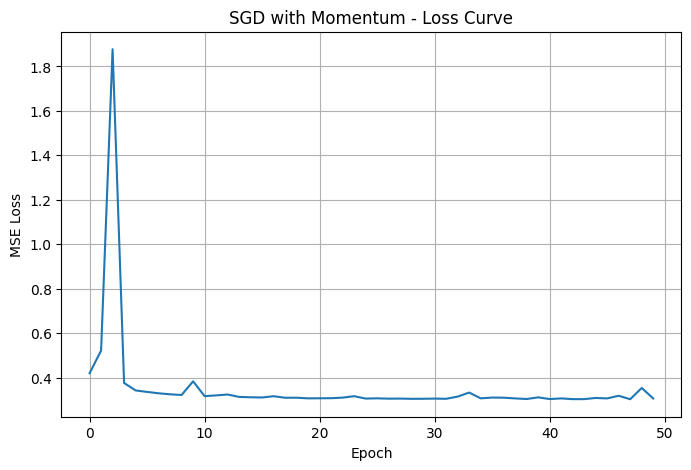

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("SGD with Momentum - Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.grid(True)
plt.show()

In [14]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Predict on test data
y_test_pred_scaled = X_test_poly_scaled @ weights

# Convert predictions back to original scale
y_test_pred = scaler_y.inverse_transform(
    y_test_pred_scaled.reshape(-1, 1)
).ravel()

y_test_original = y_test.values

# Calculate evaluation metrics
mse = mean_squared_error(y_test_original, y_test_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_original, y_test_pred)
r2 = r2_score(y_test_original, y_test_pred)

print("SGD with Momentum Results")
print("-------------------------")
print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R2 Score:", r2)

SGD with Momentum Results
-------------------------
MSE: 4354913164.807956
RMSE: 65991.76588641916
MAE: 47117.36844928526
R2 Score: 0.6676676337601093


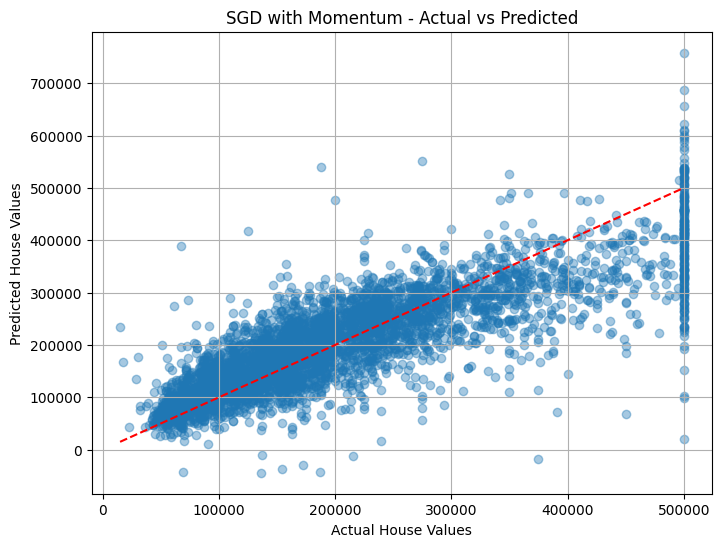

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test_original, y_test_pred, alpha=0.4)

plt.plot(
    [y_test_original.min(), y_test_original.max()],
    [y_test_original.min(), y_test_original.max()],
    'r--'
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("SGD with Momentum - Actual vs Predicted")

plt.grid(True)
plt.show()

In [16]:
results_sgd = {
    "Optimizer": "SGD with Momentum",
    "MSE": mse,
    "RMSE": rmse,
    "MAE": mae,
    "R2": r2
}

print(results_sgd)

{'Optimizer': 'SGD with Momentum', 'MSE': 4354913164.807956, 'RMSE': np.float64(65991.76588641916), 'MAE': 47117.36844928526, 'R2': 0.6676676337601093}
